<a href="https://colab.research.google.com/github/hitoshitoshi/SoloMuse/blob/main/SoloMuse_v2_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SoloMuse v2.1 — beat-aligned retrain

What changed from v2, and why:

| v2 problem | v2.1 fix |
| --- | --- |
| Fixed 0.5 s steps (`120/bpm` bug), ignoring each song's tempo: 88% of solo notes vanished | 16th-note steps cut from **each song's own beats** |
| A held note and a repeated note looked the same | Tokens are **note-on / note-off / hold** |
| "Solo" = guitar notes that don't overlap, so short chord stabs counted as solo; bass leaked in | Whole **single-note line tracks** are the targets; harmony comes from **every other pitched part** (12 pitch classes + bass note) |
| Chord input lagged one step behind the note being predicted | Model sees the harmony **at the step it is predicting**, plus the position in the bar |
| Output written at a different step length than the input was read at | Solo is rendered on the **input song's own beat grid**, with accents |
| Train/val split by window, 13 stored transpositions (3 GB) | Split **by song**; random transposition on the fly (~170 MB dataset) |
| Half of all training steps are a silent lead, so the model learned to sit out | A **density** input (how many notes in the surrounding bar) — a busyness knob at generation time |

Also learns from single-note melody lines on other instruments (vocal lines, sax, synth leads), and is told which instrument family each line is — it generates as guitar.

**How to run:** Runtime → Change runtime type → **GPU**. Then Runtime → Run all. Training is resumable: if Colab disconnects, run all again and it continues from the last finished epoch. Everything is saved under `OUT_DIR` on Drive.

In [ ]:
# 1. Setup
!pip -q install pretty_midi
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print("Not running in Colab")
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - switch to a GPU runtime before training")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4


In [ ]:
# 2. Settings
DRIVE_MIDI = "/content/drive/MyDrive/midi_files"     # folder with the training .mid files
OUT_DIR    = "/content/drive/MyDrive/solomuse_v21"   # dataset, checkpoints, log and generated solos are saved here
SMOKE = False                                        # True = tiny quick run to check the pipeline end to end

import os
os.makedirs(OUT_DIR, exist_ok=True)
INPUT_MIDI = os.path.join(OUT_DIR, "input.mid")      # the song to solo over: put a copy of input.mid in OUT_DIR on Drive

## Data pipeline (beat grid, track roles, harmony features, tokens)

In [ ]:
# Data pipeline: definitions only, nothing runs here.
import os
import numpy as np
import pretty_midi


class Config:
    # ---- paths (overridden in the notebook) ----
    MIDI_FOLDER = "/content/midi_files"
    OUT_DIR = "/content/drive/MyDrive/solomuse_v21"

    # ---- time grid: steps cut from each song's own beats ----
    STEPS_PER_BEAT = 4            # 16th notes
    MAX_POS = 32                  # metric position = steps since the last downbeat (clipped)

    # ---- which tracks are what ----
    LEAD_PROGRAMS = range(24, 32)   # General MIDI guitars (pretty_midi is 0-indexed)
    ALL_LINES = False                # also learn from single-note lines on other instruments (vocal melodies, sax...)
    GUITAR_FAMILY = 3               # program // 8; the model is told which family each line is, and plays guitar
    BASS_PROGRAMS = range(32, 40)
    MIN_MONO_SHARE = 0.85           # share of onsets that are single notes
    MAX_SUSTAIN_OVERLAP = 0.3       # share of notes still ringing when the next one starts (arpeggios are high)
    MIN_LINE_MEDIAN_PITCH = 55      # G3: single-note lines below this are riffs/bass, not leads
    MIN_LEAD_NOTES = 64
    MAX_GRID_OFFSET = 0.2           # median onset distance from the grid, in steps (rejects un-quantized MIDI)
    MIN_HARMONY_COVERAGE = 0.5      # share of lead-note steps that have some harmony under them

    # ---- tokens: note-on per pitch, NOTE_OFF, HOLD (= nothing new happens) ----
    LOW, HIGH = 40, 88              # E2..E6
    N_PITCH = HIGH - LOW + 1        # 49
    NOTE_OFF = N_PITCH              # 49
    HOLD = N_PITCH + 1              # 50
    VOCAB = N_PITCH + 2             # 51
    HARM_DIM = 24                   # 12 pitch classes sounding + 12 one-hot for the bass note

    # ---- note-density control: onsets in the bar, bucketed (0 | 1-2 | 3-5 | 6-9 | 10+) ----
    DENSITY_EDGES = (1, 3, 6, 10)
    N_DENSITY = 5

    # ---- training windows ----
    SEQ_LEN = 256                   # 16 beats = 4 bars of 4/4
    HOP = 128
    MIN_ONSETS_PER_WINDOW = 8


# --------------------------------------------------------------------------- grid
def make_grid(pm, cfg):
    """Step start times (16ths of each beat, following tempo changes) and metric position per step."""
    beats = pm.get_beats()
    if len(beats) < 4:
        return None, None
    b = np.append(beats, beats[-1] + (beats[-1] - beats[-2]))
    frac = np.arange(cfg.STEPS_PER_BEAT) / cfg.STEPS_PER_BEAT
    grid = (b[:-1, None] + np.diff(b)[:, None] * frac).ravel()
    downs = pm.get_downbeats()
    marks = np.zeros(len(grid), bool)
    di = np.searchsorted(grid, downs - 1e-6)
    marks[di[di < len(grid)]] = True
    k = np.arange(len(grid))
    last = np.maximum.accumulate(np.where(marks, k, 0))
    pos = np.clip(k - last, 0, cfg.MAX_POS - 1).astype(np.uint8)
    return grid, pos


def step_ends(grid):
    return np.append(grid[1:], grid[-1] + (grid[-1] - grid[-2]))


def snap(grid, t):
    i = np.clip(np.searchsorted(grid, t), 1, len(grid) - 1)
    return np.where(np.abs(grid[i - 1] - t) <= np.abs(grid[i] - t), i - 1, i)


def note_step_ranges(notes, grid):
    """Inclusive (k0, k1) of the steps each note sounds in (needs >= 10% overlap of the step)."""
    ends = step_ends(grid)
    ln = ends - grid
    st = np.array([n.start for n in notes]); en = np.array([n.end for n in notes])
    k0 = np.searchsorted(ends - 0.1 * ln, st, side="right")
    k1 = np.searchsorted(grid + 0.1 * ln, en, side="left") - 1
    short = k1 < k0  # very short notes: the step they start in
    k_on = np.clip(np.searchsorted(grid, st, side="right") - 1, 0, len(grid) - 1)
    k0 = np.where(short, k_on, k0); k1 = np.where(short, k_on, k1)
    return np.clip(k0, 0, len(grid) - 1), np.clip(k1, 0, len(grid) - 1)


# --------------------------------------------------------------------------- tracks
def track_profile(inst):
    notes = sorted(inst.notes, key=lambda n: n.start)
    s = np.array([n.start for n in notes]); e = np.array([n.end for n in notes])
    groups = np.split(np.arange(len(notes)), np.where(np.diff(s) > 0.03)[0] + 1)
    mono = float(np.mean([len(g) == 1 for g in groups]))
    gs = np.array([s[g[0]] for g in groups]); ge = np.array([e[g].max() for g in groups])
    overlap = float(np.mean(ge[:-1] - gs[1:] > 0.05)) if len(groups) > 1 else 0.0
    return mono, overlap, float(np.median([n.pitch for n in notes]))


def classify_tracks(pm, cfg):
    """leads: single-note lines used as training targets (guitar only unless ALL_LINES); melody: any single-note line (kept out of harmony);
    bass: bass programs; harmony: everything else that is pitched."""
    leads, melody, bass, harmony = [], [], [], []
    for i, inst in enumerate(pm.instruments):
        if inst.is_drum or not inst.notes:
            continue
        if inst.program in cfg.BASS_PROGRAMS:
            bass.append(i); continue
        is_line = False
        if len(inst.notes) >= 16:
            mono, ovl, med = track_profile(inst)
            is_line = mono >= cfg.MIN_MONO_SHARE and ovl <= cfg.MAX_SUSTAIN_OVERLAP and med >= cfg.MIN_LINE_MEDIAN_PITCH
        if is_line:
            melody.append(i)
            if len(inst.notes) >= cfg.MIN_LEAD_NOTES and (cfg.ALL_LINES or inst.program in cfg.LEAD_PROGRAMS):
                leads.append(i)
        else:
            harmony.append(i)
    return leads, melody, bass, harmony


def harmony_features(pm, harmony_idx, bass_idx, grid, cfg):
    """(T, 24) uint8: pitch classes sounding in the harmony tracks + one-hot of the lowest bass note."""
    T = len(grid)
    H = np.zeros((T, cfg.HARM_DIM), np.uint8)

    def lowest_note(idx, chroma):
        low = np.full(T, 128, np.int16)
        notes = [n for i in idx for n in pm.instruments[i].notes]
        if notes:
            k0, k1 = note_step_ranges(notes, grid)
            for n, a, b in zip(notes, k0, k1):
                if chroma:
                    H[a:b + 1, n.pitch % 12] = 1
                seg = low[a:b + 1]
                np.minimum(seg, n.pitch, out=seg)
        return low

    low_bass = lowest_note(bass_idx, chroma=False)
    low_harm = lowest_note(harmony_idx, chroma=True)
    low = np.where(low_bass < 128, low_bass, low_harm)  # bass part where it plays, else lowest harmony note
    k = np.where(low < 128)[0]
    H[k, 12 + (low[k] % 12)] = 1
    return H


# --------------------------------------------------------------------------- lead line -> tokens
def lead_tokens(inst, grid, cfg):
    """Monophonic token sequence: note-on (pitch - LOW), NOTE_OFF, HOLD. Returns tokens, grid offset stats."""
    notes = sorted(inst.notes, key=lambda n: (n.start, -n.pitch))
    mono = []
    for n in notes:  # top note of each onset group
        if mono and n.start - mono[-1].start <= 0.03:
            continue
        mono.append(n)
    T = len(grid)
    tok = np.full(T, cfg.HOLD, np.uint8)
    if not mono:
        return tok, 1.0, 0
    st = np.array([n.start for n in mono]); en = np.array([n.end for n in mono])
    a = snap(grid, st); b = snap(grid, en)
    ln = step_ends(grid) - grid
    offset = float(np.median(np.abs(grid[a] - st) / ln[a]))
    keep, seen = [], set()
    for i in range(len(mono)):
        if a[i] in seen or not (cfg.LOW <= mono[i].pitch <= cfg.HIGH):
            continue
        seen.add(a[i]); keep.append(i)
    for j, i in enumerate(keep):
        nxt = a[keep[j + 1]] if j + 1 < len(keep) else T
        end = min(max(b[i], a[i] + 1), nxt)
        tok[a[i]] = mono[i].pitch - cfg.LOW
        if end < nxt and end < T:
            tok[end] = cfg.NOTE_OFF
    return tok, offset, len(keep)


def density_buckets(tok, pos, cfg):
    """Per step: how busy the line is in the current bar (onsets in the bar), as a bucket 0..4.
    Constant across the bar, so it says how many notes, not where. Training shows the model the real value;
    at generation time you choose it, like a 'busyness' knob."""
    bar = np.cumsum(pos == 0)
    on = (tok < cfg.N_PITCH).astype(np.int64)
    per_bar = np.bincount(bar, weights=on)
    return np.digitize(per_bar[bar], cfg.DENSITY_EDGES).astype(np.uint8)


def tokens_to_notes(tok, grid, cfg, pos=None, velocity_fn=None, program=29):
    """Inverse of lead_tokens: notes start at their step's time and end at NOTE_OFF or the next note."""
    inst = pretty_midi.Instrument(program=program, name="AI Solo")
    ends = step_ends(grid)
    cur, start = None, 0
    for k, t in enumerate(list(tok) + [cfg.NOTE_OFF]):
        t = int(t)
        if cur is not None and (t == cfg.NOTE_OFF or t < cfg.N_PITCH):
            vel = velocity_fn(start) if velocity_fn else 96
            inst.notes.append(pretty_midi.Note(int(vel), cur + cfg.LOW, float(grid[start]),
                                               float(grid[k]) if k < len(grid) else float(ends[-1])))
            cur = None
        if t < cfg.N_PITCH:
            cur, start = t, k
    return inst


# --------------------------------------------------------------------------- one file -> training examples
def process_file(path, cfg):
    try:
        pm = pretty_midi.PrettyMIDI(path)
    except Exception:
        return [], "unreadable"
    leads, melody, bass, harmony = classify_tracks(pm, cfg)
    if not leads:
        return [], "no lead line"
    grid, pos = make_grid(pm, cfg)
    if grid is None:
        return [], "no beat grid"
    H = harmony_features(pm, harmony, bass, grid, cfg)
    out, why = [], "kept"
    for li in leads:
        tok, offset, n_on = lead_tokens(pm.instruments[li], grid, cfg)
        if offset > cfg.MAX_GRID_OFFSET:
            why = "off the beat grid"; continue
        sounding = np.zeros(len(tok), bool)
        on = False
        for k, t in enumerate(tok):  # steps where the lead is sounding
            if t < cfg.N_PITCH: on = True
            elif t == cfg.NOTE_OFF: on = False
            sounding[k] = on
        cov = float(H[sounding, :12].any(1).mean()) if sounding.any() else 0.0
        if cov < cfg.MIN_HARMONY_COVERAGE:
            why = "no harmony under the lead"; continue
        on_steps = set(np.where(tok < cfg.N_PITCH)[0].tolist())
        if any(len(on_steps & o) >= 0.9 * max(len(on_steps), 1) for o in [set(np.where(e["tokens"] < cfg.N_PITCH)[0].tolist()) for e in out]):
            continue  # doubled part (same line on two tracks)
        out.append(dict(file=os.path.basename(path), track=li, program=int(pm.instruments[li].program),
                        family=int(pm.instruments[li].program) // 8,
                        tokens=tok, harm=H, pos=pos, onsets=n_on, grid_offset=offset, coverage=cov))
    return out, why if not out else "kept"

## Model, training, generation, scoring

In [ ]:
# Model, training, generation and scoring: definitions only, nothing runs here.
import os, csv, copy, math, time, zlib, random
import numpy as np
import pretty_midi
import torch
import torch.nn as nn
import torch.nn.functional as F



# --------------------------------------------------------------------------- dataset
def is_val(name, val_share=0.1):
    """Song-level split, stable across runs (no window of a validation song is ever trained on)."""
    return (zlib.crc32(name.encode()) % 1000) < val_share * 1000


class WindowDataset(torch.utils.data.Dataset):
    def __init__(self, examples, cfg, split, augment, guitar_oversample=2):
        self.ex = [e for e in examples if is_val(e["file"]) == (split == "val")]
        self.cfg, self.augment = cfg, augment
        self.dens = [density_buckets(e["tokens"], e["pos"], cfg) for e in self.ex]
        self.index = []
        L = cfg.SEQ_LEN
        for i, e in enumerate(self.ex):
            t = e["tokens"]
            for s in range(0, max(len(t) - L - 1, 0) + 1, cfg.HOP):
                if (t[s:s + L + 1] < cfg.N_PITCH).sum() >= cfg.MIN_ONSETS_PER_WINDOW:
                    reps = guitar_oversample if (augment and e["family"] == cfg.GUITAR_FAMILY) else 1
                    self.index += [(i, s)] * reps

    def __len__(self):
        return len(self.index)

    def __getitem__(self, j):
        cfg = self.cfg
        i, s = self.index[j]
        e = self.ex[i]
        L = cfg.SEQ_LEN
        tok = e["tokens"][s:s + L + 1].astype(np.int64)
        harm = e["harm"][s:s + L + 1].astype(np.float32)
        pos = e["pos"][s:s + L + 1].astype(np.int64)
        dens = self.dens[i][s:s + L + 1].astype(np.int64)
        if len(tok) < L + 1:  # short song: pad with silence
            pad = L + 1 - len(tok)
            tok = np.concatenate([tok, np.full(pad, cfg.HOLD)])
            harm = np.concatenate([harm, np.zeros((pad, cfg.HARM_DIM), np.float32)])
            pos = np.concatenate([pos, np.zeros(pad, np.int64)])
            dens = np.concatenate([dens, np.zeros(pad, np.int64)])
        if self.augment:  # transpose the whole window (line + harmony) to a random key that keeps the line in range
            on = tok < cfg.N_PITCH
            lo, hi = (tok[on].min(), tok[on].max()) if on.any() else (0, cfg.N_PITCH - 1)
            ks = [k for k in range(-5, 7) if lo + k >= 0 and hi + k < cfg.N_PITCH]
            k = random.choice(ks) if ks else 0
            tok = np.where(on, tok + k, tok)
            harm = np.concatenate([np.roll(harm[:, :12], k, 1), np.roll(harm[:, 12:], k, 1)], 1)
        return (torch.from_numpy(tok[:-1]), torch.from_numpy(harm[1:]), torch.from_numpy(pos[1:]),
                torch.from_numpy(dens[1:]), torch.tensor(e["family"]), torch.from_numpy(tok[1:]))


# --------------------------------------------------------------------------- model
class SoloTransformer(nn.Module):
    """Predicts the token at step t+1 from the line so far plus the harmony, bar position and density AT step t+1."""

    def __init__(self, cfg, d=256, heads=8, layers=6, ff=1024, dropout=0.1):
        super().__init__()
        self.tok = nn.Embedding(cfg.VOCAB, d)
        self.harm = nn.Sequential(nn.Linear(cfg.HARM_DIM, d), nn.GELU(), nn.Linear(d, d))
        self.metric = nn.Embedding(cfg.MAX_POS, d)
        self.density = nn.Embedding(cfg.N_DENSITY, d)
        self.abs = nn.Embedding(cfg.SEQ_LEN, d)
        self.family = nn.Embedding(16, d)
        layer = nn.TransformerEncoderLayer(d, heads, ff, dropout, activation="gelu", batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d)
        self.out = nn.Linear(d, cfg.VOCAB)
        self.drop = nn.Dropout(dropout)

    def forward(self, tok, harm, pos, dens, family):
        T = tok.size(1)
        x = (self.tok(tok) + self.harm(harm) + self.metric(pos) + self.density(dens)
             + self.abs(torch.arange(T, device=tok.device))[None] + self.family(family)[:, None])
        mask = nn.Transformer.generate_square_subsequent_mask(T, device=tok.device)
        return self.out(self.norm(self.enc(self.drop(x), mask=mask, is_causal=True)))


# --------------------------------------------------------------------------- training
@torch.no_grad()
def evaluate(model, loader, cfg, device, max_batches=None):
    """Validation loss, the same loss with the harmony removed (does the model use it?), and note-level accuracy."""
    model.eval()
    tot = abl = n = 0.0
    on_hit = on_n = 0
    for b, (tok, harm, pos, dens, fam, y) in enumerate(loader):
        if max_batches and b >= max_batches:
            break
        tok, harm, pos, dens, fam, y = (z.to(device) for z in (tok, harm, pos, dens, fam, y))
        with torch.autocast(device_type=device.split(":")[0], dtype=torch.float16, enabled=device.startswith("cuda")):
            lg = model(tok, harm, pos, dens, fam).float()
            lg0 = model(tok, torch.zeros_like(harm), pos, dens, fam).float()
        tot += F.cross_entropy(lg.reshape(-1, cfg.VOCAB), y.reshape(-1), reduction="sum").item()
        abl += F.cross_entropy(lg0.reshape(-1, cfg.VOCAB), y.reshape(-1), reduction="sum").item()
        n += y.numel()
        m = y < cfg.N_PITCH
        on_hit += (lg.argmax(-1)[m] == y[m]).sum().item(); on_n += m.sum().item()
    model.train()
    return dict(val_loss=tot / n, val_loss_no_harmony=abl / n, note_pitch_acc=on_hit / max(on_n, 1))


def train(model, train_ds, val_ds, cfg, out_dir, device, epochs=40, batch_size=64, lr=5e-4, weight_decay=0.05,
          warmup_steps=1000, patience=6, num_workers=2, max_steps_per_epoch=None, log=print):
    """Resumable: re-running picks up from out_dir/last.pt. Keeps the best model (by val loss) in out_dir/best.pt."""
    os.makedirs(out_dir, exist_ok=True)
    tl = torch.utils.data.DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=num_workers,
                                     drop_last=True, pin_memory=device.startswith("cuda"), persistent_workers=num_workers > 0)
    vl = torch.utils.data.DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers)
    steps_per_epoch = min(len(tl), max_steps_per_epoch or len(tl))
    total = epochs * steps_per_epoch
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay, betas=(0.9, 0.98))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / warmup_steps) *
                                              (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * min(s / total, 1.0)))))
    scaler = torch.amp.GradScaler("cuda", enabled=device.startswith("cuda"))
    start, best, bad = 0, float("inf"), 0
    last = os.path.join(out_dir, "last.pt")
    if os.path.exists(last):
        ck = torch.load(last, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
        start, best, bad = ck["epoch"] + 1, ck["best"], ck["bad"]
        log(f"Resuming from epoch {start + 1} (best val loss so far {best:.4f})")
    logf = os.path.join(out_dir, "log.csv")
    for ep in range(start, epochs):
        t0, run, cnt = time.time(), 0.0, 0
        for step, (tok, harm, pos, dens, fam, y) in enumerate(tl):
            if step >= steps_per_epoch:
                break
            tok, harm, pos, dens, fam, y = (z.to(device, non_blocking=True) for z in (tok, harm, pos, dens, fam, y))
            with torch.autocast(device_type=device.split(":")[0], dtype=torch.float16, enabled=device.startswith("cuda")):
                loss = F.cross_entropy(model(tok, harm, pos, dens, fam).reshape(-1, cfg.VOCAB).float(), y.reshape(-1))
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run += loss.item(); cnt += 1
        m = evaluate(model, vl, cfg, device)
        m.update(epoch=ep + 1, train_loss=run / max(cnt, 1), lr=sched.get_last_lr()[0], minutes=(time.time() - t0) / 60)
        log(f"epoch {ep + 1:2d} | train {m['train_loss']:.4f} | val {m['val_loss']:.4f} | val without harmony "
            f"{m['val_loss_no_harmony']:.4f} | note pitch acc {m['note_pitch_acc']:.3f} | {m['minutes']:.1f} min")
        new = not os.path.exists(logf)
        with open(logf, "a", newline="") as f:
            w = csv.DictWriter(f, fieldnames=list(m)); new and w.writeheader(); w.writerow(m)
        if m["val_loss"] < best - 1e-4:
            best, bad = m["val_loss"], 0
            torch.save(dict(model=model.state_dict(), epoch=ep, metrics=m), os.path.join(out_dir, "best.pt"))
        else:
            bad += 1
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                        epoch=ep, best=best, bad=bad), last)
        if bad >= patience:
            log(f"Stopping early: no improvement for {patience} epochs.")
            break
    return best


# --------------------------------------------------------------------------- generation
def prepare_song(path, cfg):
    """Backing harmony for a song: every pitched part except single-note melody lines, on the song's own beat grid."""
    pm = pretty_midi.PrettyMIDI(path)
    leads, melody, bass, harmony = classify_tracks(pm, cfg)
    grid, pos = make_grid(pm, cfg)
    H = harmony_features(pm, harmony, bass, grid, cfg)
    return dict(pm=pm, grid=grid, pos=pos, harm=H, melody=melody, bass=bass, harmony=harmony)


@torch.no_grad()
def generate(model, song, cfg, device, density=3, temperature=1.0, top_p=0.95, low=52, high=86, family=None,
             silence_beats=4, silence_push=1.5, seed=0):
    """Samples one token per 16th step. Steps are cut from the input song's beats, so the solo stays in time.
    density: 0-4 (or one value per step) = how busy the solo should be; 3 is about 6-9 notes per bar.
    After `silence_beats` beats of silence, HOLD is pushed down by `silence_push` (logits) so it doesn't stall."""
    model.eval()
    family = cfg.GUITAR_FAMILY if family is None else family
    rng = torch.Generator().manual_seed(seed)
    harm = torch.tensor(song["harm"], dtype=torch.float32, device=device)
    pos = torch.tensor(song["pos"].astype(np.int64), device=device)
    fam = torch.tensor([family], device=device)
    T, L = len(song["grid"]), cfg.SEQ_LEN
    dens = torch.as_tensor(np.broadcast_to(np.asarray(density, np.int64), (T,)).copy(), device=device)
    toks = [cfg.HOLD]
    sounding, quiet = False, 0
    allowed = torch.zeros(cfg.VOCAB, dtype=torch.bool)
    allowed[max(low - cfg.LOW, 0):min(high - cfg.LOW, cfg.N_PITCH - 1) + 1] = True
    allowed[cfg.NOTE_OFF] = allowed[cfg.HOLD] = True
    for k in range(1, T):
        s = max(0, k - L)
        x = torch.tensor(toks[s:k], device=device)[None]
        with torch.autocast(device_type=device.split(":")[0], dtype=torch.float16, enabled=device.startswith("cuda")):
            lg = model(x, harm[s + 1:k + 1][None], pos[s + 1:k + 1][None], dens[s + 1:k + 1][None], fam)[0, -1].float().cpu()
        lg[~allowed] = -float("inf")
        if not sounding:
            lg[cfg.NOTE_OFF] = -float("inf")
            if quiet >= silence_beats * cfg.STEPS_PER_BEAT:
                lg[cfg.HOLD] -= silence_push
        p = F.softmax(lg / temperature, -1)
        if top_p < 1.0:
            sp, si = torch.sort(p, descending=True)
            cut = torch.cumsum(sp, 0) - sp > top_p
            sp[cut] = 0
            p = torch.zeros_like(p).scatter(0, si, sp)
            p /= p.sum()
        t = int(torch.multinomial(p, 1, generator=rng))
        toks.append(t)
        if t < cfg.N_PITCH:
            sounding, quiet = True, 0
        elif t == cfg.NOTE_OFF:
            sounding, quiet = False, 0
        elif not sounding:
            quiet += 1
    return np.array(toks, np.uint8)


def density_by_bar(song, levels):
    """Per-step density from a per-bar plan, repeated across the song: e.g. (3, 3, 2, 0) = busy, busy, lighter, rest."""
    bar = np.cumsum(song["pos"] == 0) - 1
    levels = np.asarray(levels, np.int64)
    return levels[np.clip(bar, 0, None) % len(levels)]


def density_from_real_solo(song, examples, cfg, seed=0):
    """Borrow the phrasing (busy and quiet bars) of a real guitar line from the training data."""
    r = np.random.default_rng(seed)
    guitar = ([e for e in examples if e["family"] == cfg.GUITAR_FAMILY and e["onsets"] >= 200]
              or [e for e in examples if e["onsets"] >= 50])
    e = guitar[r.integers(len(guitar))]
    d = density_buckets(e["tokens"], e["pos"], cfg)
    bars = d[e["pos"] == 0]
    active = np.where(bars > 0)[0]
    bars = bars[active[0]:active[-1] + 1]  # from its first to its last played bar
    print(f"Phrasing borrowed from {e['file']} (track {e['track']}), {len(bars)} bars")
    return density_by_bar(song, bars)


def accent(pos, seed=0):
    """Velocity from the bar position (downbeat > beat > 8th > 16th) plus a little human variation."""
    r = np.random.default_rng(seed)
    def vel(k):
        p = int(pos[k])
        base = 106 if p == 0 else 98 if p % 4 == 0 else 88 if p % 2 == 0 else 80
        return int(np.clip(base + r.integers(-6, 7), 1, 127))
    return vel


def render(song, tokens, cfg, out_path, program=29, mute_melody=True, seed=0):
    """Writes the input song (minus its own melody lines, unless mute_melody=False) plus the generated solo."""
    out = copy.deepcopy(song["pm"])  # keeps the song's tempo map, meter and markers
    out.instruments = [inst for i, inst in enumerate(out.instruments) if not (mute_melody and i in song["melody"])]
    solo = tokens_to_notes(tokens, song["grid"], cfg, velocity_fn=accent(song["pos"], seed), program=program)
    solo.name = "AI Solo"
    out.instruments.append(solo)
    out.write(out_path)
    return solo


# --------------------------------------------------------------------------- scoring
MAJOR = np.array([6.35, 2.23, 3.48, 2.33, 4.38, 4.09, 2.52, 5.19, 2.39, 3.66, 2.29, 2.88])
MINOR = np.array([6.33, 2.68, 3.52, 5.38, 2.60, 3.53, 2.54, 4.75, 3.98, 2.69, 3.34, 3.17])


def score_solo(song, tokens, cfg, n_shifts=300, seed=0):
    """Chord tones = note's pitch class is sounding in the backing at its onset step. Compared with random pitches
    and with the same solo slid to random other places in the song (which keeps the key, breaks the chord timing)."""
    H = song["harm"][:, :12].astype(bool)
    on = np.where(tokens < cfg.N_PITCH)[0]
    if len(on) == 0:
        return dict(notes=0)
    pc = (tokens[on].astype(int) + cfg.LOW) % 12
    has = H[on].any(1)
    ct = float(H[on, pc][has].mean()) if has.any() else float("nan")
    r = np.random.default_rng(seed)
    T = len(tokens)
    null = []
    for _ in range(n_shifts):
        sh = (on + r.integers(T // 10, T - T // 10)) % T
        m = H[sh].any(1)
        null.append(H[sh, pc][m].mean() if m.any() else np.nan)
    null = np.array(null)
    rand = float(np.mean([H[on, r.integers(0, 12, len(on))][has].mean() for _ in range(50)]))
    prof = H.sum(0).astype(float)
    best = max(((np.corrcoef(prof, np.roll(t, k))[0, 1], k, m) for k in range(12) for m, t in (("maj", MAJOR), ("min", MINOR))))
    scale = {(best[1] + d) % 12 for d in ((0, 2, 4, 5, 7, 9, 11) if best[2] == "maj" else (0, 2, 3, 5, 7, 8, 10))}
    spb = cfg.STEPS_PER_BEAT
    gaps = np.diff(on)  # steps between note starts: the rhythm
    return dict(notes=int(len(on)),
                notes_per_beat=round(len(on) / (T / spb), 2),
                gaps_between_notes_in_16ths={int(k): int(v) for k, v in zip(*np.unique(np.minimum(gaps, 16), return_counts=True))},
                chord_tone_share=round(ct, 3),
                same_notes_random_place=round(float(np.nanmean(null)), 3),
                beats_random_places_pct=round(float(np.nanmean(null < ct)) * 100, 1),
                random_pitch=round(rand, 3),
                in_key=round(float(np.mean([p in scale for p in pc])), 3))

In [ ]:
# 3. Build the dataset (about 5 minutes; skipped if it already exists on Drive)
import pickle, shutil, collections, time
from multiprocessing import get_context

cfg = Config()
DATA_PATH = os.path.join(OUT_DIR, "dataset_v21.pkl")

def _work(path):
    return process_file(path, cfg)

if os.path.exists(DATA_PATH):
    print("Loading", DATA_PATH)
    examples = pickle.load(open(DATA_PATH, "rb"))["examples"]
else:
    local = "/content/midi_files"
    if not os.path.exists(local):
        print("Copying MIDI files from Drive to the runtime (faster to read)...")
        shutil.copytree(DRIVE_MIDI, local, ignore=shutil.ignore_patterns("processed_checkpoints"))
    files = sorted(os.path.join(local, f) for f in os.listdir(local) if f.lower().endswith(".mid"))
    if SMOKE:
        files = files[:300]
    t0 = time.time()
    with get_context("fork").Pool(os.cpu_count()) as p:
        res = p.map(_work, files, chunksize=10)
    examples = [e for r, _ in res for e in r]
    print(f"{len(files)} files in {(time.time() - t0) / 60:.1f} min:", dict(collections.Counter(w for _, w in res)))
    pickle.dump(dict(config={k: getattr(cfg, k) for k in dir(cfg) if k.isupper()}, examples=examples), open(DATA_PATH, "wb"))
    print("Saved", DATA_PATH)

fam = collections.Counter(e["family"] for e in examples)
print(f"{len(examples)} lines from {len({e['file'] for e in examples})} songs | guitar lines: {fam[cfg.GUITAR_FAMILY]} | "
      f"note onsets: {sum(e['onsets'] for e in examples):,}")

Copying MIDI files from Drive to the runtime (faster to read)...


/usr/local/lib/python3.13/dist-packages/pretty_midi/pretty_midi.py:122: RuntimeWarning: Tempo, Key or Time signature change events found on non-zero tracks.  This is not a valid type 0 or type 1 MIDI file.  Tempo, Key or Time Signature may be wrong.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/pretty_midi/pretty_midi.py:122: RuntimeWarning: Tempo, Key or Time signature change events found on non-zero tracks.  This is not a valid type 0 or type 1 MIDI file.  Tempo, Key or Time Signature may be wrong.
  warnings.warn(


5165 files in 8.6 min: {'unreadable': 170, 'no lead line': 3769, 'kept': 1020, 'off the beat grid': 132, 'no harmony under the lead': 74}
Saved /content/drive/MyDrive/solomuse_v21/dataset_v21.pkl
1196 lines from 1020 songs | guitar lines: 1196 | note onsets: 369,108


In [ ]:
# 4. Train (about 1-2 hours on a T4; resumable)
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
train_ds = WindowDataset(examples, cfg, "train", augment=True)
val_ds = WindowDataset(examples, cfg, "val", augment=False)
print(f"train windows {len(train_ds):,} | val windows {len(val_ds):,} | val songs {len({e['file'] for e in val_ds.ex})}")

MODEL_KW = dict(d=128, heads=4, layers=2, ff=256, dropout=0.1) if SMOKE else dict(d=256, heads=8, layers=6, ff=1024, dropout=0.1)
model = SoloTransformer(cfg, **MODEL_KW).to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters on {device}")

CKPT_DIR = os.path.join(OUT_DIR, "smoke_checkpoints" if SMOKE else "checkpoints")
train(model, train_ds, val_ds, cfg, CKPT_DIR, device,
      epochs=2 if SMOKE else 40, batch_size=64, lr=5e-4, warmup_steps=50 if SMOKE else 1000, patience=6,
      num_workers=0 if SMOKE else 2, max_steps_per_epoch=20 if SMOKE else None)

train windows 20,650 | val windows 1,012 | val songs 95
4,916,531 parameters on cuda


/tmp/ipykernel_837/1168568680.py:142: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


epoch  1 | train 1.5484 | val 1.0254 | val without harmony 1.0413 | note pitch acc 0.190 | 0.5 min
epoch  2 | train 0.8082 | val 0.7299 | val without harmony 0.7623 | note pitch acc 0.397 | 0.5 min
epoch  3 | train 0.6561 | val 0.6539 | val without harmony 0.7062 | note pitch acc 0.468 | 0.6 min
epoch  4 | train 0.5893 | val 0.6115 | val without harmony 0.6692 | note pitch acc 0.497 | 0.6 min
epoch  5 | train 0.5462 | val 0.5803 | val without harmony 0.6335 | note pitch acc 0.515 | 0.6 min
epoch  6 | train 0.5158 | val 0.5653 | val without harmony 0.6197 | note pitch acc 0.530 | 0.6 min
epoch  7 | train 0.4922 | val 0.5499 | val without harmony 0.6051 | note pitch acc 0.545 | 0.6 min
epoch  8 | train 0.4731 | val 0.5403 | val without harmony 0.5908 | note pitch acc 0.556 | 0.6 min
epoch  9 | train 0.4573 | val 0.5299 | val without harmony 0.5851 | note pitch acc 0.563 | 0.6 min
epoch 10 | train 0.4451 | val 0.5204 | val without harmony 0.5730 | note pitch acc 0.567 | 0.6 min
epoch 11 |

0.5109053072722062

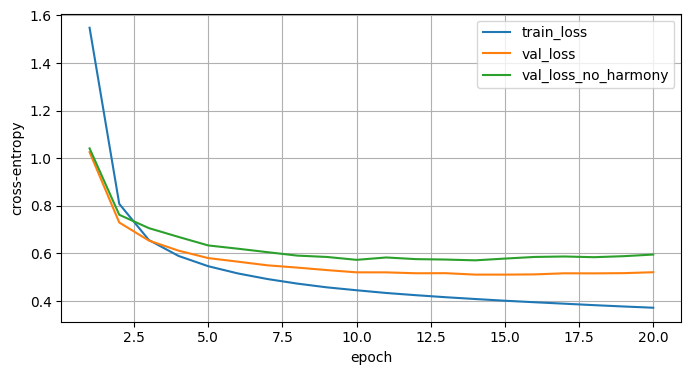

 epoch  train_loss  val_loss  val_loss_no_harmony  note_pitch_acc
     1      1.5484    1.0254               1.0413          0.1902
     2      0.8082    0.7299               0.7623          0.3972
     3      0.6561    0.6539               0.7062          0.4677
     4      0.5893    0.6115               0.6692          0.4972
     5      0.5462    0.5803               0.6335          0.5153
     6      0.5158    0.5653               0.6197          0.5300
     7      0.4922    0.5499               0.6051          0.5455
     8      0.4731    0.5403               0.5908          0.5560
     9      0.4573    0.5299               0.5851          0.5633
    10      0.4451    0.5204               0.5730          0.5665
    11      0.4337    0.5203               0.5829          0.5787
    12      0.4244    0.5166               0.5759          0.5829
    13      0.4159    0.5169               0.5742          0.5866
    14      0.4083    0.5109               0.5709          0.5876
    15    

In [ ]:
# 5. Training curve. If "val without harmony" sits clearly above "val", the model is using the chords.
import pandas as pd, matplotlib.pyplot as plt
log = pd.read_csv(os.path.join(CKPT_DIR, "log.csv"))
ax = log.plot(x="epoch", y=["train_loss", "val_loss", "val_loss_no_harmony"], figsize=(8, 4), grid=True)
ax.set_ylabel("cross-entropy"); plt.show()
print(log[["epoch", "train_loss", "val_loss", "val_loss_no_harmony", "note_pitch_acc"]].round(4).to_string(index=False))

In [ ]:
# 6. Generate solos over INPUT_MIDI and score them
import json
best = torch.load(os.path.join(CKPT_DIR, "best.pt"), map_location=device, weights_only=False)
model.load_state_dict(best["model"]); model.eval()
print("Using best checkpoint from epoch", best["epoch"] + 1, "| val loss", round(best["metrics"]["val_loss"], 4))

if not os.path.exists(INPUT_MIDI):
    raise FileNotFoundError(f"Put the song to solo over at {INPUT_MIDI} (upload input.mid to that Drive folder), then rerun this cell.")
song = prepare_song(INPUT_MIDI, cfg)
print(f"{len(song['grid'])} steps | steps with harmony: {song['harm'][:, :12].any(1).mean():.0%} | "
      f"muted melody tracks: {song['melody']}")

# density = how busy each bar is: 0 rest, 1 = 1-2 notes, 2 = 3-5, 3 = 6-9, 4 = 10+ notes per bar.
# A single number keeps it constant; density_by_bar repeats a per-bar plan; density_from_real_solo copies the
# busy/quiet phrasing of a real guitar line from the training data. temperature/top_p = how adventurous the notes are.
SETTINGS = [
    dict(name="d2", density=2, temperature=1.0, top_p=0.95, seed=0),
    dict(name="d3", density=3, temperature=1.0, top_p=0.95, seed=0),
    dict(name="phrased_3320", density=density_by_bar(song, (3, 3, 2, 0)), temperature=1.0, top_p=0.95, seed=0),
    dict(name="real_phrasing_s0", density=density_from_real_solo(song, examples, cfg, seed=0), temperature=1.0, top_p=0.95, seed=0),
    dict(name="real_phrasing_s1", density=density_from_real_solo(song, examples, cfg, seed=1), temperature=1.0, top_p=0.95, seed=1),
    dict(name="d3_t0.9", density=3, temperature=0.9, top_p=0.95, seed=0),
]
GEN_DIR = os.path.join(OUT_DIR, "generated"); os.makedirs(GEN_DIR, exist_ok=True)
results = {}
for s in SETTINGS:
    s = dict(s); name = s.pop("name")
    toks = generate(model, song, cfg, device, **s)
    path = os.path.join(GEN_DIR, f"solo_{name}.mid")
    render(song, toks, cfg, path)
    results[name] = score_solo(song, toks, cfg)
    print(name, json.dumps(results[name]))
print("Saved to", GEN_DIR)

Using best checkpoint from epoch 14 | val loss 0.5109
2256 steps | steps with harmony: 90% | muted melody tracks: [4]
Phrasing borrowed from 4904.mid (track 12), 94 bars
Phrasing borrowed from 3041.mid (track 5), 173 bars
d2 {"notes": 806, "notes_per_beat": 1.43, "gaps_between_notes_in_16ths": {"2": 540, "3": 2, "4": 235, "6": 16, "8": 1, "10": 7, "12": 2, "14": 2}, "chord_tone_share": 0.525, "same_notes_random_place": 0.42, "beats_random_places_pct": 100.0, "random_pitch": 0.267, "in_key": 0.995}
d3 {"notes": 1136, "notes_per_beat": 2.01, "gaps_between_notes_in_16ths": {"1": 557, "2": 434, "3": 11, "4": 3, "6": 130}, "chord_tone_share": 0.307, "same_notes_random_place": 0.295, "beats_random_places_pct": 62.7, "random_pitch": 0.269, "in_key": 0.606}
phrased_3320 {"notes": 700, "notes_per_beat": 1.24, "gaps_between_notes_in_16ths": {"1": 13, "2": 637, "3": 1, "4": 7, "6": 2, "10": 4, "16": 35}, "chord_tone_share": 0.531, "same_notes_random_place": 0.479, "beats_random_places_pct": 93.3,

In [ ]:
# 7. Download the generated MIDI files (optional)
try:
    from google.colab import files
    for f in sorted(os.listdir(GEN_DIR)):
        files.download(os.path.join(GEN_DIR, f))
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>